In [1]:
import pandas as pd
import numpy as np
%pip install matplotlib.pyplot
import seaborn as sns
import matplotlib.pyplot as plt

ERROR: Could not find a version that satisfies the requirement matplotlib.pyplot (from versions: none)
ERROR: No matching distribution found for matplotlib.pyplot


Note: you may need to restart the kernel to use updated packages.


In [2]:
df = pd.read_csv(r"C:\Users\win11\Downloads\house_prices.csv\house_prices.csv")

In [3]:
df.head()

,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,...,facing,overlooking,Society,Bathroom,Balcony,Car Parking,Ownership,Super Area,Dimensions,Plot Area
0,0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",42 Lac,6000.0,thane,500 sqft,Ready to Move,10 out of 11,Resale,...,NaN,NaN,Srushti Siddhi Mangal Murti Complex,1,2,NaN,NaN,NaN,NaN,NaN
1,1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,98 Lac,13799.0,thane,473 sqft,Ready to Move,3 out of 22,Resale,...,East,Garden/Park,Dosti Vihar,2,NaN,1 Open,Freehold,NaN,NaN,NaN
2,2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,1.40 Cr,17500.0,thane,779 sqft,Ready to Move,10 out of 29,Resale,...,East,Garden/Park,Sunrise by Kalpataru,2,NaN,1 Covered,Freehold,NaN,NaN,NaN
3,3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,25 Lac,NaN,thane,530 sqft,Ready to Move,1 out of 3,Resale,...,NaN,NaN,NaN,1,1,NaN,NaN,NaN,NaN,NaN
4,4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",1.60 Cr,18824.0,thane,635 sqft,Ready to Move,20 out of 42,Resale,...,West,"Garden/Park, Main Road",TenX Habitat Raymond Realty,2,NaN,1 Covered,Co-operative Society,NaN,NaN,NaN


In [4]:
df.describe()

,Index,Price (in rupees),Dimensions,Plot Area
count,187531.000000,1.698660e+05,0.0,0.0
mean,93765.000000,7.583772e+03,NaN,NaN
std,54135.681003,2.724171e+04,NaN,NaN
min,0.000000,0.000000e+00,NaN,NaN
25%,46882.500000,4.297000e+03,NaN,NaN
50%,93765.000000,6.034000e+03,NaN,NaN
75%,140647.500000,9.450000e+03,NaN,NaN
max,187530.000000,6.700000e+06,NaN,NaN


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 187531 entries, 0 to 187530
Data columns (total 21 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Index              187531 non-null  int64  
 1   Title              187531 non-null  str    
 2   Description        184508 non-null  str    
 3   Amount(in rupees)  187531 non-null  str    
 4   Price (in rupees)  169866 non-null  float64
 5   location           187531 non-null  str    
 6   Carpet Area        106858 non-null  str    
 7   Status             186916 non-null  str    
 8   Floor              180454 non-null  str    
 9   Transaction        187448 non-null  str    
 10  Furnishing         184634 non-null  str    
 11  facing             117298 non-null  str    
 12  overlooking        106095 non-null  str    
 13  Society            77853 non-null   str    
 14  Bathroom           186703 non-null  str    
 15  Balcony            138596 non-null  str    
 16  Car Parking  

In [6]:
df.isnull().sum()


Index                     0
Title                     0
Description            3023
Amount(in rupees)         0
Price (in rupees)     17665
location                  0
Carpet Area           80673
Status                  615
Floor                  7077
Transaction              83
Furnishing             2897
facing                70233
overlooking           81436
Society              109678
Bathroom                828
Balcony               48935
Car Parking          103357
Ownership             65517
Super Area           107685
Dimensions           187531
Plot Area            187531
dtype: int64

In [7]:
[df.isnull().mean()*100]

[Index                  0.000000
 Title                  0.000000
 Description            1.612000
 Amount(in rupees)      0.000000
 Price (in rupees)      9.419776
 location               0.000000
 Carpet Area           43.018488
 Status                 0.327946
 Floor                  3.773776
 Transaction            0.044259
 Furnishing             1.544811
 facing                37.451408
 overlooking           43.425354
 Society               58.485264
 Bathroom               0.441527
 Balcony               26.094352
 Car Parking           55.114621
 Ownership             34.936624
 Super Area            57.422506
 Dimensions           100.000000
 Plot Area            100.000000
 dtype: float64]

In [8]:
df.drop((df.columns[df.isnull().mean()*100 > 50.0]), axis=1, inplace=True)

In [9]:
df.isnull().mean()*100

Index                 0.000000
Title                 0.000000
Description           1.612000
Amount(in rupees)     0.000000
Price (in rupees)     9.419776
location              0.000000
Carpet Area          43.018488
Status                0.327946
Floor                 3.773776
Transaction           0.044259
Furnishing            1.544811
facing               37.451408
overlooking          43.425354
Bathroom              0.441527
Balcony              26.094352
Ownership            34.936624
dtype: float64

In [10]:
categorical_features = df.select_dtypes(include=['object']).columns
numerical_features = df.select_dtypes(include=['int64', 'float64']).columns

C:\Users\win11\AppData\Local\Temp\ipykernel_3456\2973811786.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include=['object']).columns


In [11]:
categorical_features

Index(['Title', 'Description', 'Amount(in rupees)', 'location', 'Carpet Area',
       'Status', 'Floor', 'Transaction', 'Furnishing', 'facing', 'overlooking',
       'Bathroom', 'Balcony', 'Ownership'],
      dtype='str')

In [12]:
numerical_features

Index(['Index', 'Price (in rupees)'], dtype='str')

In [13]:
df['location'].unique()

<StringArray>
[        'thane',   'navi-mumbai',        'nagpur',        'mumbai',
     'ahmedabad',     'bangalore',       'chennai',       'gurgaon',
     'hyderabad',        'indore',        'jaipur',       'kolkata',
       'lucknow',     'new-delhi',         'noida',          'pune',
          'agra',    'ahmadnagar',     'allahabad',    'aurangabad',
      'badlapur',       'belgaum',       'bhiwadi',      'bhiwandi',
        'bhopal',   'bhubaneswar',    'chandigarh',    'coimbatore',
      'dehradun',      'durgapur',     'ernakulam',     'faridabad',
     'ghaziabad',           'goa', 'greater-noida',        'guntur',
      'guwahati',       'gwalior',      'haridwar',      'jabalpur',
    'jamshedpur',       'jodhpur',        'kalyan',        'kanpur',
         'kochi',     'kozhikode',      'ludhiana',       'madurai',
     'mangalore',        'mohali',        'mysore',        'nashik',
       'navsari',       'nellore',      'palakkad',       'palghar',
     'panchkula',   

In [14]:
df["Transaction"].unique()

<StringArray>
['Resale', 'New Property', nan, 'Other', 'Rent/Lease']
Length: 5, dtype: str

In [15]:
def clean_data(df):
    for col in categorical_features:
        df[col] = df[col].fillna(df[col].mode()[0])

    return df

In [16]:
df=clean_data(df)

In [17]:
df.isnull().sum()



Index                    0
Title                    0
Description              0
Amount(in rupees)        0
Price (in rupees)    17665
location                 0
Carpet Area              0
Status                   0
Floor                    0
Transaction              0
Furnishing               0
facing                   0
overlooking              0
Bathroom                 0
Balcony                  0
Ownership                0
dtype: int64

<Axes: xlabel='Price (in rupees)', ylabel='Count'>

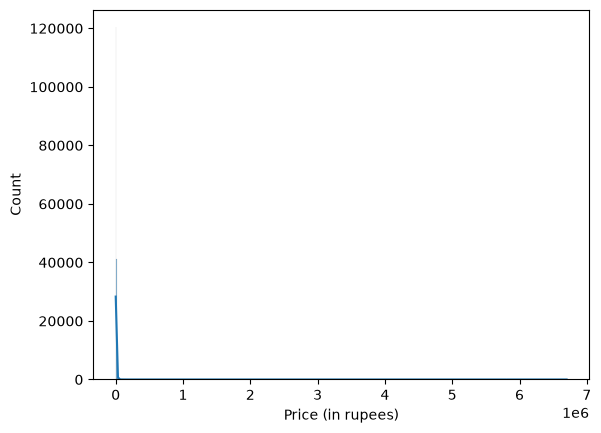

In [18]:
sns.histplot(df['Price (in rupees)'], kde=True)

In [19]:
df[df["Price (in rupees)"].isnull()]["Amount(in rupees)"].head(20)

3             25 Lac 
24     Call for Price
37     Call for Price
44            70 Lac 
69           1.55 Cr 
70           2.65 Cr 
71            53 Lac 
83     Call for Price
84            22 Lac 
94            25 Lac 
103             4 Cr 
104           48 Lac 
107         68.6 Lac 
131    Call for Price
168          1.60 Cr 
177    Call for Price
201           36 Lac 
206          2.99 Cr 
224           72 Lac 
235    Call for Price
Name: Amount(in rupees), dtype: str

In [20]:
(df["Price (in rupees)"] * df["Carpet Area"].str.extract(r'(\d+)').astype(float).squeeze()).head(10)

0     3000000.0
1     6526927.0
2    13632500.0
3           NaN
4    11953240.0
5     6618000.0
6     1395900.0
7    10435000.0
8    10000000.0
9    10035000.0
dtype: float64

In [21]:
import regex as re

In [22]:
df.head()

,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,Furnishing,facing,overlooking,Bathroom,Balcony,Ownership
0,0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",42 Lac,6000.0,thane,500 sqft,Ready to Move,10 out of 11,Resale,Unfurnished,East,Main Road,1,2,Freehold
1,1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,98 Lac,13799.0,thane,473 sqft,Ready to Move,3 out of 22,Resale,Semi-Furnished,East,Garden/Park,2,2,Freehold
2,2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,1.40 Cr,17500.0,thane,779 sqft,Ready to Move,10 out of 29,Resale,Unfurnished,East,Garden/Park,2,2,Freehold
3,3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,25 Lac,NaN,thane,530 sqft,Ready to Move,1 out of 3,Resale,Unfurnished,East,Main Road,1,1,Freehold
4,4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",1.60 Cr,18824.0,thane,635 sqft,Ready to Move,20 out of 42,Resale,Unfurnished,West,"Garden/Park, Main Road",2,2,Co-operative Society


In [23]:
import re
import numpy as np

def parse_amount(val):
    if pd.isna(val):
        return np.nan
    val = str(val).strip()
    if "Call for Price" in val:
        return np.nan
    match = re.match(r'([\d.]+)\s*(Cr|Lac)', val, re.IGNORECASE)
    if not match:
        return np.nan
    num, unit = float(match.group(1)), match.group(2).lower()
    return num * 1e7 if unit == "cr" else num * 1e5

df["Amount(in rupees)"] = df["Amount(in rupees)"].apply(parse_amount)

In [24]:
df.head()

,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,Furnishing,facing,overlooking,Bathroom,Balcony,Ownership
0,0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",4200000.0,6000.0,thane,500 sqft,Ready to Move,10 out of 11,Resale,Unfurnished,East,Main Road,1,2,Freehold
1,1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,9800000.0,13799.0,thane,473 sqft,Ready to Move,3 out of 22,Resale,Semi-Furnished,East,Garden/Park,2,2,Freehold
2,2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,14000000.0,17500.0,thane,779 sqft,Ready to Move,10 out of 29,Resale,Unfurnished,East,Garden/Park,2,2,Freehold
3,3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,2500000.0,NaN,thane,530 sqft,Ready to Move,1 out of 3,Resale,Unfurnished,East,Main Road,1,1,Freehold
4,4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",16000000.0,18824.0,thane,635 sqft,Ready to Move,20 out of 42,Resale,Unfurnished,West,"Garden/Park, Main Road",2,2,Co-operative Society


In [25]:
df["Amount(in rupees)"].dtype

dtype('float64')

array([[<Axes: title={'center': 'Index'}>,
        <Axes: title={'center': 'Price (in rupees)'}>]], dtype=object)

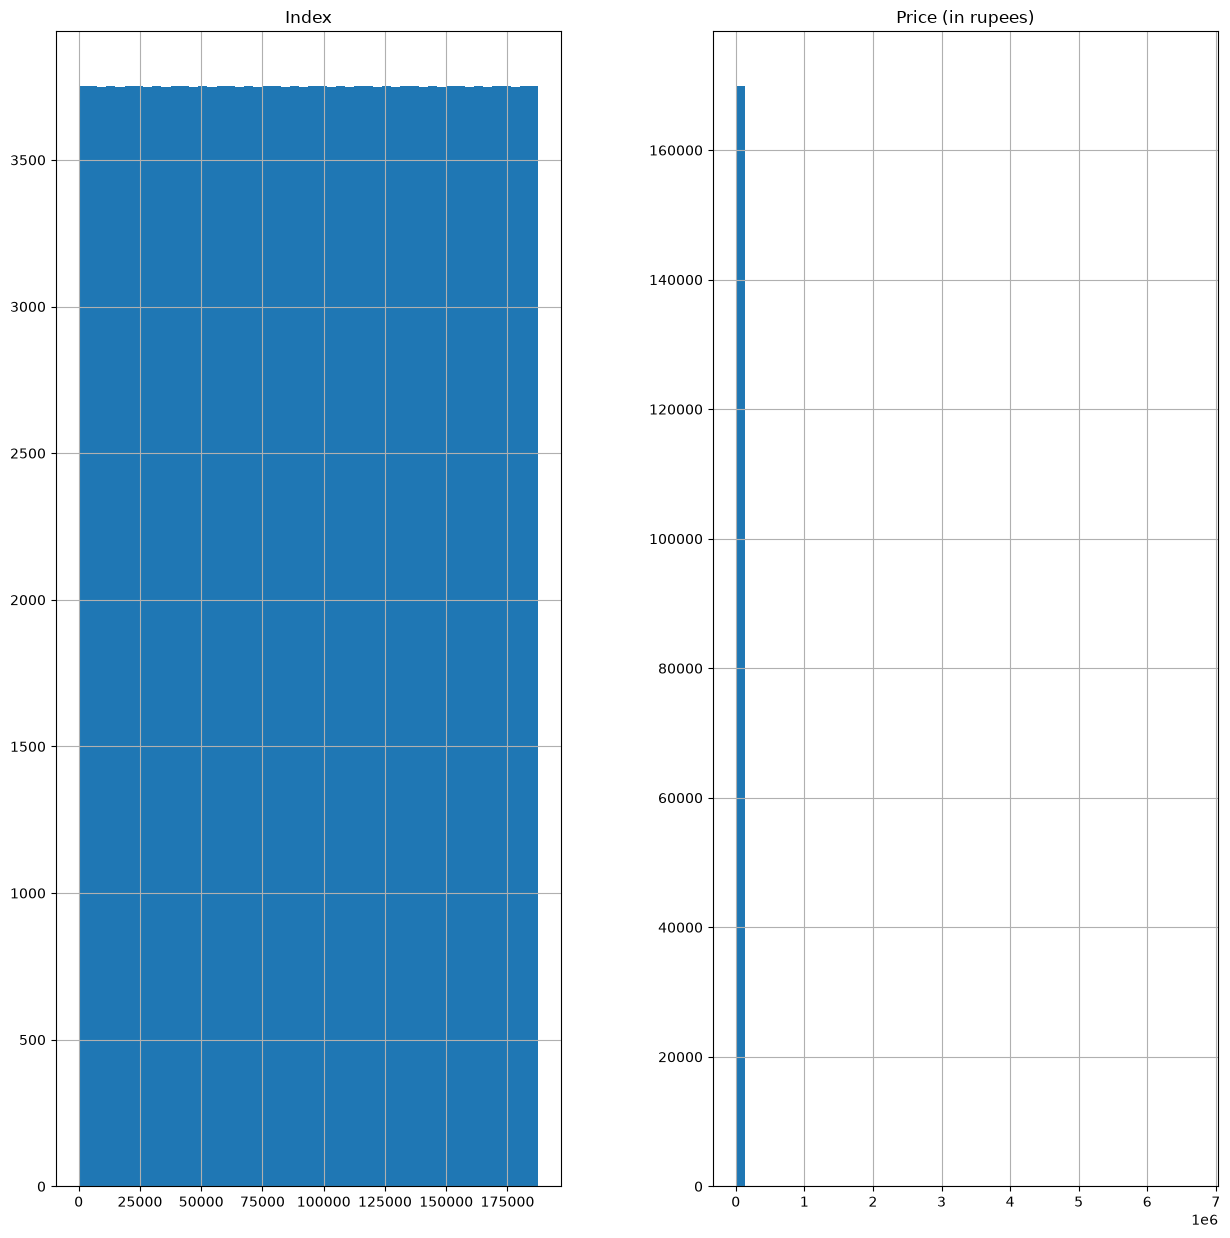

In [26]:
df[numerical_features].hist(figsize=(15, 15), bins=50)

<Axes: xlabel='Price (in rupees)', ylabel='Count'>

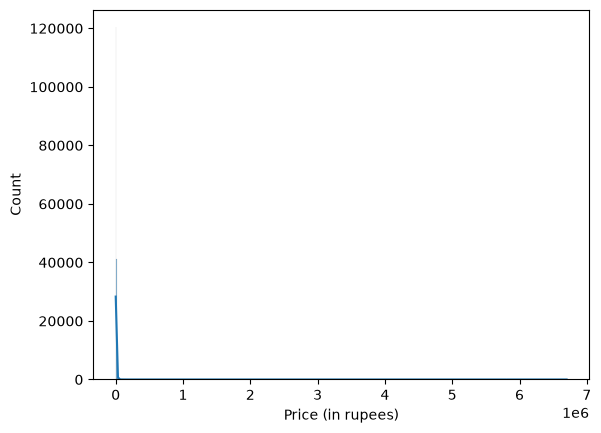

In [27]:
sns.histplot(df['Price (in rupees)'], kde=True)

In [28]:
categorical_features

Index(['Title', 'Description', 'Amount(in rupees)', 'location', 'Carpet Area',
       'Status', 'Floor', 'Transaction', 'Furnishing', 'facing', 'overlooking',
       'Bathroom', 'Balcony', 'Ownership'],
      dtype='str')

In [29]:
df['location'].value_counts()

location
new-delhi      27599
bangalore      24030
kolkata        22380
gurgaon        20070
ahmedabad      12750
               ...  
navsari           30
nellore           30
palakkad          30
pondicherry       30
solapur           30
Name: count, Length: 81, dtype: int64

In [30]:
df['location'].unique()

<StringArray>
[        'thane',   'navi-mumbai',        'nagpur',        'mumbai',
     'ahmedabad',     'bangalore',       'chennai',       'gurgaon',
     'hyderabad',        'indore',        'jaipur',       'kolkata',
       'lucknow',     'new-delhi',         'noida',          'pune',
          'agra',    'ahmadnagar',     'allahabad',    'aurangabad',
      'badlapur',       'belgaum',       'bhiwadi',      'bhiwandi',
        'bhopal',   'bhubaneswar',    'chandigarh',    'coimbatore',
      'dehradun',      'durgapur',     'ernakulam',     'faridabad',
     'ghaziabad',           'goa', 'greater-noida',        'guntur',
      'guwahati',       'gwalior',      'haridwar',      'jabalpur',
    'jamshedpur',       'jodhpur',        'kalyan',        'kanpur',
         'kochi',     'kozhikode',      'ludhiana',       'madurai',
     'mangalore',        'mohali',        'mysore',        'nashik',
       'navsari',       'nellore',      'palakkad',       'palghar',
     'panchkula',   

In [32]:
counts = df['location'].value_counts()
rare = counts[counts < 100].index

In [33]:
rare.nunique()

17

In [34]:
df['location_grouped'] = df['location'].replace(rare, 'other')


In [35]:
df

,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,Furnishing,facing,overlooking,Bathroom,Balcony,Ownership,location_grouped
0,0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",4200000.0,6000.0,thane,500 sqft,Ready to Move,10 out of 11,Resale,Unfurnished,East,Main Road,1,2,Freehold,thane
1,1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,9800000.0,13799.0,thane,473 sqft,Ready to Move,3 out of 22,Resale,Semi-Furnished,East,Garden/Park,2,2,Freehold,thane
2,2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,14000000.0,17500.0,thane,779 sqft,Ready to Move,10 out of 29,Resale,Unfurnished,East,Garden/Park,2,2,Freehold,thane
3,3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,2500000.0,NaN,thane,530 sqft,Ready to Move,1 out of 3,Resale,Unfurnished,East,Main Road,1,1,Freehold,thane
4,4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",16000000.0,18824.0,thane,635 sqft,Ready to Move,20 out of 42,Resale,Unfurnished,West,"Garden/Park, Main Road",2,2,Co-operative Society,thane
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
187526,187526,3 BHK Ready to Occupy Flat for sale in Bollywo...,This magnificent 3 BHK Flat is available for s...,6300000.0,3225.0,zirakpur,1000 sqft,Ready to Move,2 out of 4,New Property,Semi-Furnished,East,Garden/Park,3,3,Freehold,zirakpur
187527,187527,3 BHK Ready to Occupy Flat for sale in Sushma ...,Have a look at this immaculate 3 BHK flat for ...,5500000.0,3274.0,zirakpur,1000 sqft,Ready to Move,4 out of 6,Resale,Unfurnished,North - East,"Garden/Park, Main Road",3,2,Freehold,zirakpur
187528,187528,3 BHK Ready to Occupy Flat for sale in Bollywo...,"Gazipur, Zirakpur has an appealing 3 BHK flat ...",7600000.0,4343.0,zirakpur,1250 sqft,Ready to Move,1 out of 3,Resale,Furnished,East,"Garden/Park, Main Road",3,2,Freehold,zirakpur
187529,187529,2 BHK Ready to Occupy Flat for sale in Friends...,Up for immediate sale is a 2 BHK apartment in ...,3000000.0,4231.0,zirakpur,1000 sqft,Ready to Move,2 out of 2,Resale,Semi-Furnished,East,Main Road,2,2,Freehold,zirakpur


In [36]:
df = pd.get_dummies(df, columns=['location_grouped'], drop_first=True)

In [37]:
df.columns

Index(['Index', 'Title', 'Description', 'Amount(in rupees)',
       'Price (in rupees)', 'location', 'Carpet Area', 'Status', 'Floor',
       'Transaction', 'Furnishing', 'facing', 'overlooking', 'Bathroom',
       'Balcony', 'Ownership', 'location_grouped_ahmedabad',
       'location_grouped_allahabad', 'location_grouped_aurangabad',
       'location_grouped_badlapur', 'location_grouped_bangalore',
       'location_grouped_bhiwadi', 'location_grouped_bhopal',
       'location_grouped_bhubaneswar', 'location_grouped_chandigarh',
       'location_grouped_chennai', 'location_grouped_coimbatore',
       'location_grouped_dehradun', 'location_grouped_durgapur',
       'location_grouped_ernakulam', 'location_grouped_faridabad',
       'location_grouped_ghaziabad', 'location_grouped_goa',
       'location_grouped_greater-noida', 'location_grouped_guntur',
       'location_grouped_gurgaon', 'location_grouped_guwahati',
       'location_grouped_gwalior', 'location_grouped_haridwar',
       'lo

In [38]:
df['Furnishing'].unique()

<StringArray>
['Unfurnished', 'Semi-Furnished', 'Furnished']
Length: 3, dtype: str

In [39]:
df['facing'].unique()

<StringArray>
[        'East',         'West', 'North - East',        'North',
 'North - West',        'South',  'South -West', 'South - East']
Length: 8, dtype: str

In [40]:
df['Ownership'].unique()

<StringArray>
['Freehold', 'Co-operative Society', 'Power Of Attorney', 'Leasehold']
Length: 4, dtype: str

In [41]:
df['Price (in rupees)'].skew()

np.float64(177.11336980623076)

In [42]:
df['Price (in rupees)'].nlargest(10)

181234    6700000.0
147912    4500000.0
180679    4500000.0
176536    4041600.0
174894    3450000.0
175013    2669100.0
180481    1200000.0
174925     322727.0
183490     291667.0
172107     282609.0
Name: Price (in rupees), dtype: float64

In [43]:
df[172107:172108]

,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,...,location_grouped_thrissur,location_grouped_trichy,location_grouped_trivandrum,location_grouped_udaipur,location_grouped_vadodara,location_grouped_vapi,location_grouped_varanasi,location_grouped_vijayawada,location_grouped_visakhapatnam,location_grouped_zirakpur
172107,172107,2 BHK Ready to Occupy Flat for sale Chamaraja ...,This attractive 2 BHK apartment can be found f...,13000000.0,282609.0,mysore,1000 sqft,Ready to Move,1 out of 3,Resale,...,False,False,False,False,False,False,False,False,False,False


In [44]:
df['Price (in rupees)'].nsmallest(10)

154245    0.0
165311    0.0
165838    0.0
166029    0.0
167515    0.0
174916    0.0
175044    0.0
176399    0.0
176805    0.0
183352    0.0
Name: Price (in rupees), dtype: float64

In [45]:
print(df['Amount(in rupees)'].skew())
df['Amount(in rupees)'].nlargest(10)

270.2559400379884


181234    1.400300e+10
176536    5.100400e+09
174894    3.967500e+09
175013    2.298000e+09
183303    8.000000e+08
51966     6.000000e+08
50321     5.500000e+08
52058     5.500000e+08
52387     5.200000e+08
51965     5.000000e+08
Name: Amount(in rupees), dtype: float64

<Axes: xlabel='Amount(in rupees)', ylabel='Count'>

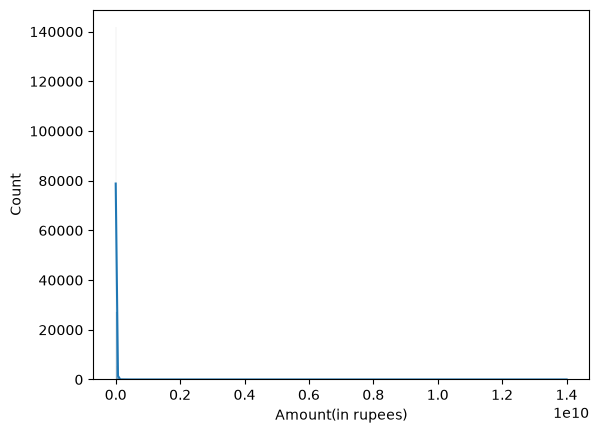

In [46]:
sns.histplot(df['Amount(in rupees)'], kde=True)

In [47]:
df.describe()

,Index,Amount(in rupees),Price (in rupees)
count,187531.000000,1.778470e+05,1.698660e+05
mean,93765.000000,1.198134e+07,7.583772e+03
std,54135.681003,3.943827e+07,2.724171e+04
min,0.000000,1.000000e+05,0.000000e+00
25%,46882.500000,4.840000e+06,4.297000e+03
50%,93765.000000,7.800000e+06,6.034000e+03
75%,140647.500000,1.450000e+07,9.450000e+03
max,187530.000000,1.400300e+10,6.700000e+06


In [48]:
print((df['Amount(in rupees)'] > df['Amount(in rupees)'].quantile(0.99)).sum())
print(df['Amount(in rupees)'].quantile([0.95, 0.99, 0.995, 0.999]))

1182
0.950     33900000.0
0.990     70000000.0
0.995     89600000.0
0.999    125000000.0
Name: Amount(in rupees), dtype: float64


In [49]:
q1=df['Amount(in rupees)'].quantile(0.75)

In [50]:
q1

np.float64(14500000.0)

In [51]:
q2=df['Amount(in rupees)'].quantile(0.25)

In [52]:
q2

np.float64(4840000.0)

In [53]:
df["Amount(in rupees)"].max()

np.float64(14003000000.0)

In [54]:
iqr = q1 - q2

In [55]:
lower_bound = q2 - 1.5 * iqr

In [56]:
upper_bound = q1 + 1.5* iqr

<Axes: xlabel='Amount(in rupees)'>

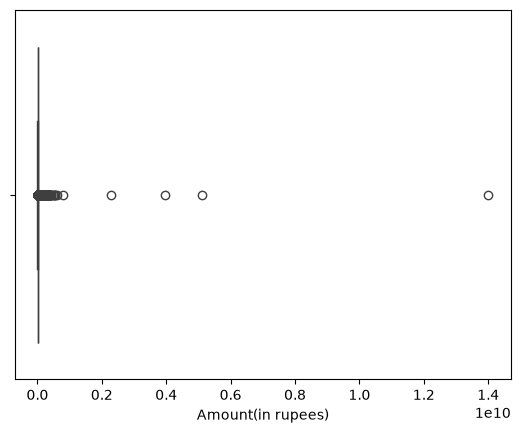

In [57]:
sns.boxplot(x=df['Amount(in rupees)'])

In [58]:
df[df["Amount(in rupees)"]==1.400300e+10].value_counts()

Index   Title                                                                                   Description                                                                                                                                                                                                                                                                                                                                                                                                          Amount(in rupees)  Price (in rupees)  location  Carpet Area  Status         Floor       Transaction   Furnishing   facing  overlooking  Bathroom  Balcony  Ownership  location_grouped_ahmedabad  location_grouped_allahabad  location_grouped_aurangabad  location_grouped_badlapur  location_grouped_bangalore  location_grouped_bhiwadi  location_grouped_bhopal  location_grouped_bhubaneswar  location_grouped_chandigarh  location_grouped_chennai  location_grouped_coimbatore  location_grouped_dehradun  l

In [59]:
df = df[(df["Amount(in rupees)"] >= lower_bound) & (df["Amount(in rupees)"] <= upper_bound)]

In [60]:

outliers = df[(df['Amount(in rupees)'] < lower_bound) | (df['Amount(in rupees)'] > upper_bound)]
print(len(outliers), "rows outside bound")
outliers['Amount(in rupees)'].describe()

0 rows outside bound


count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: Amount(in rupees), dtype: float64

In [61]:
upper_bound

np.float64(28990000.0)

In [62]:
df['Amount(in rupees)'].skew()


np.float64(1.1336906020245414)

<Axes: xlabel='Amount(in rupees)', ylabel='Count'>

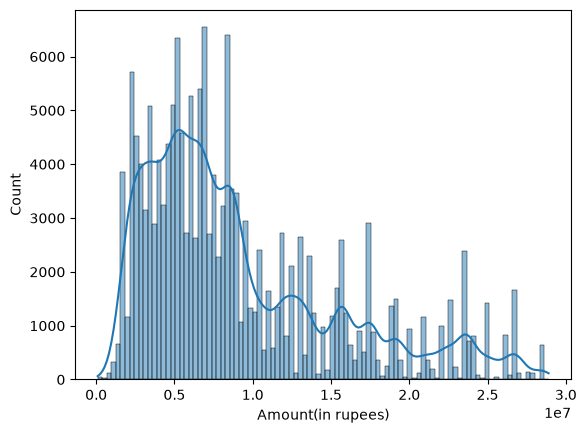

In [63]:
sns.histplot(df['Amount(in rupees)'], kde=True)

<Axes: xlabel='Total_Price_log', ylabel='Count'>

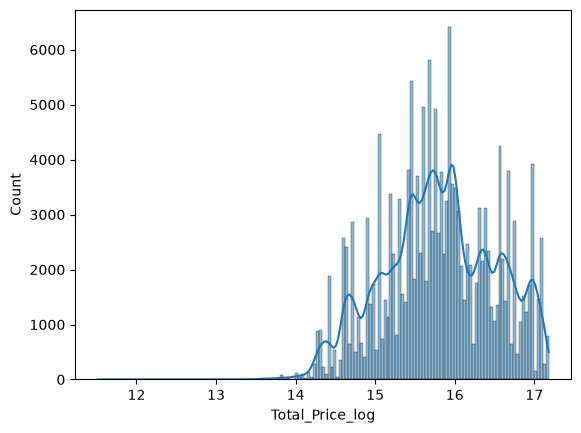

In [64]:
df['Total_Price_log'] = np.log1p(df['Amount(in rupees)'])
sns.histplot(df['Total_Price_log'], kde=True)

In [65]:
df[df['Total_Price_log'] < 13]['Amount(in rupees)'].describe()

count        47.000000
mean     268510.638298
std      106627.729557
min      100000.000000
25%      200000.000000
50%      260000.000000
75%      355000.000000
max      430000.000000
Name: Amount(in rupees), dtype: float64

In [66]:
df

,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,...,location_grouped_trichy,location_grouped_trivandrum,location_grouped_udaipur,location_grouped_vadodara,location_grouped_vapi,location_grouped_varanasi,location_grouped_vijayawada,location_grouped_visakhapatnam,location_grouped_zirakpur,Total_Price_log
0,0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",4200000.0,6000.0,thane,500 sqft,Ready to Move,10 out of 11,Resale,...,False,False,False,False,False,False,False,False,False,15.250595
1,1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,9800000.0,13799.0,thane,473 sqft,Ready to Move,3 out of 22,Resale,...,False,False,False,False,False,False,False,False,False,16.097893
2,2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,14000000.0,17500.0,thane,779 sqft,Ready to Move,10 out of 29,Resale,...,False,False,False,False,False,False,False,False,False,16.454568
3,3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,2500000.0,NaN,thane,530 sqft,Ready to Move,1 out of 3,Resale,...,False,False,False,False,False,False,False,False,False,14.731802
4,4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",16000000.0,18824.0,thane,635 sqft,Ready to Move,20 out of 42,Resale,...,False,False,False,False,False,False,False,False,False,16.588099
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
187526,187526,3 BHK Ready to Occupy Flat for sale in Bollywo...,This magnificent 3 BHK Flat is available for s...,6300000.0,3225.0,zirakpur,1000 sqft,Ready to Move,2 out of 4,New Property,...,False,False,False,False,False,False,False,False,True,15.656060
187527,187527,3 BHK Ready to Occupy Flat for sale in Sushma ...,Have a look at this immaculate 3 BHK flat for ...,5500000.0,3274.0,zirakpur,1000 sqft,Ready to Move,4 out of 6,Resale,...,False,False,False,False,False,False,False,False,True,15.520259
187528,187528,3 BHK Ready to Occupy Flat for sale in Bollywo...,"Gazipur, Zirakpur has an appealing 3 BHK flat ...",7600000.0,4343.0,zirakpur,1250 sqft,Ready to Move,1 out of 3,Resale,...,False,False,False,False,False,False,False,False,True,15.843659
187529,187529,2 BHK Ready to Occupy Flat for sale in Friends...,Up for immediate sale is a 2 BHK apartment in ...,3000000.0,4231.0,zirakpur,1000 sqft,Ready to Move,2 out of 2,Resale,...,False,False,False,False,False,False,False,False,True,14.914123


In [67]:
df['Price (in rupees)'].skew()

np.float64(249.1320192756296)

In [68]:
df.describe()

,Index,Amount(in rupees),Price (in rupees),Total_Price_log
count,165564.000000,1.655640e+05,1.589270e+05,165564.000000
mean,95040.297444,9.185406e+06,6.778726e+03,15.799563
std,55031.479967,6.320746e+06,1.666461e+04,0.702259
min,0.000000,1.000000e+05,0.000000e+00,11.512935
25%,45367.750000,4.500000e+06,4.207000e+03,15.319588
50%,96570.500000,7.200000e+06,5.818000e+03,15.789592
75%,143769.250000,1.250000e+07,8.065500e+03,16.341239
max,187530.000000,2.890000e+07,4.500000e+06,17.179352


In [69]:
df.isna().sum()

Index                                0
Title                                0
Description                          0
Amount(in rupees)                    0
Price (in rupees)                 6637
                                  ... 
location_grouped_varanasi            0
location_grouped_vijayawada          0
location_grouped_visakhapatnam       0
location_grouped_zirakpur            0
Total_Price_log                      0
Length: 81, dtype: int64

In [70]:
df.drop(columns=['Price (in rupees)'], inplace=True)

In [71]:
df

,Index,Title,Description,Amount(in rupees),location,Carpet Area,Status,Floor,Transaction,Furnishing,...,location_grouped_trichy,location_grouped_trivandrum,location_grouped_udaipur,location_grouped_vadodara,location_grouped_vapi,location_grouped_varanasi,location_grouped_vijayawada,location_grouped_visakhapatnam,location_grouped_zirakpur,Total_Price_log
0,0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",4200000.0,thane,500 sqft,Ready to Move,10 out of 11,Resale,Unfurnished,...,False,False,False,False,False,False,False,False,False,15.250595
1,1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,9800000.0,thane,473 sqft,Ready to Move,3 out of 22,Resale,Semi-Furnished,...,False,False,False,False,False,False,False,False,False,16.097893
2,2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,14000000.0,thane,779 sqft,Ready to Move,10 out of 29,Resale,Unfurnished,...,False,False,False,False,False,False,False,False,False,16.454568
3,3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,2500000.0,thane,530 sqft,Ready to Move,1 out of 3,Resale,Unfurnished,...,False,False,False,False,False,False,False,False,False,14.731802
4,4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",16000000.0,thane,635 sqft,Ready to Move,20 out of 42,Resale,Unfurnished,...,False,False,False,False,False,False,False,False,False,16.588099
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
187526,187526,3 BHK Ready to Occupy Flat for sale in Bollywo...,This magnificent 3 BHK Flat is available for s...,6300000.0,zirakpur,1000 sqft,Ready to Move,2 out of 4,New Property,Semi-Furnished,...,False,False,False,False,False,False,False,False,True,15.656060
187527,187527,3 BHK Ready to Occupy Flat for sale in Sushma ...,Have a look at this immaculate 3 BHK flat for ...,5500000.0,zirakpur,1000 sqft,Ready to Move,4 out of 6,Resale,Unfurnished,...,False,False,False,False,False,False,False,False,True,15.520259
187528,187528,3 BHK Ready to Occupy Flat for sale in Bollywo...,"Gazipur, Zirakpur has an appealing 3 BHK flat ...",7600000.0,zirakpur,1250 sqft,Ready to Move,1 out of 3,Resale,Furnished,...,False,False,False,False,False,False,False,False,True,15.843659
187529,187529,2 BHK Ready to Occupy Flat for sale in Friends...,Up for immediate sale is a 2 BHK apartment in ...,3000000.0,zirakpur,1000 sqft,Ready to Move,2 out of 2,Resale,Semi-Furnished,...,False,False,False,False,False,False,False,False,True,14.914123


In [72]:
categorical_features

Index(['Title', 'Description', 'Amount(in rupees)', 'location', 'Carpet Area',
       'Status', 'Floor', 'Transaction', 'Furnishing', 'facing', 'overlooking',
       'Bathroom', 'Balcony', 'Ownership'],
      dtype='str')

In [73]:
df.drop(columns=['Title', 'Description', 'location'], inplace=True)

# check cardinality before blanket dummy-encoding
for col in ['Status', 'Floor', 'Transaction', 'Furnishing', 'facing', 'overlooking', 'Ownership']:
    print(col, df[col].nunique())

Status 1
Floor 792
Transaction 4
Furnishing 3
facing 8
overlooking 18
Ownership 4


In [74]:
df.head()

,Index,Amount(in rupees),Carpet Area,Status,Floor,Transaction,Furnishing,facing,overlooking,Bathroom,...,location_grouped_trichy,location_grouped_trivandrum,location_grouped_udaipur,location_grouped_vadodara,location_grouped_vapi,location_grouped_varanasi,location_grouped_vijayawada,location_grouped_visakhapatnam,location_grouped_zirakpur,Total_Price_log
0,0,4200000.0,500 sqft,Ready to Move,10 out of 11,Resale,Unfurnished,East,Main Road,1,...,False,False,False,False,False,False,False,False,False,15.250595
1,1,9800000.0,473 sqft,Ready to Move,3 out of 22,Resale,Semi-Furnished,East,Garden/Park,2,...,False,False,False,False,False,False,False,False,False,16.097893
2,2,14000000.0,779 sqft,Ready to Move,10 out of 29,Resale,Unfurnished,East,Garden/Park,2,...,False,False,False,False,False,False,False,False,False,16.454568
3,3,2500000.0,530 sqft,Ready to Move,1 out of 3,Resale,Unfurnished,East,Main Road,1,...,False,False,False,False,False,False,False,False,False,14.731802
4,4,16000000.0,635 sqft,Ready to Move,20 out of 42,Resale,Unfurnished,West,"Garden/Park, Main Road",2,...,False,False,False,False,False,False,False,False,False,16.588099


In [75]:
df['overlooking'].unique()[:20]

<StringArray>
[                     'Main Road',                    'Garden/Park',
         'Garden/Park, Main Road',   'Pool, Garden/Park, Main Road',
   'Garden/Park, Pool, Main Road',              'Garden/Park, Pool',
         'Main Road, Garden/Park',   'Main Road, Garden/Park, Pool',
              'Pool, Garden/Park',                           'Pool',
   'Garden/Park, Main Road, Pool',                'Pool, Main Road',
   'Main Road, Pool, Garden/Park',   'Pool, Main Road, Garden/Park',
       'Main Road, Not Available',                'Main Road, Pool',
     'Garden/Park, Not Available', 'Pool, Main Road, Not Available']
Length: 18, dtype: str

In [76]:
# Split on comma, strip whitespace
overlooking_split = df['overlooking'].str.split(',').apply(lambda lst: [x.strip() for x in lst])

# Get all unique individual tags
all_tags = set(tag for tags in overlooking_split for tag in tags)
print(all_tags)

# Create one binary column per tag
for tag in all_tags:
    df[f'overlooking_{tag.replace("/", "_").replace(" ", "_")}'] = overlooking_split.apply(lambda tags: int(tag in tags))

df.drop(columns=['overlooking'], inplace=True)

{'Pool', 'Not Available', 'Main Road', 'Garden/Park'}


In [77]:
df

,Index,Amount(in rupees),Carpet Area,Status,Floor,Transaction,Furnishing,facing,Bathroom,Balcony,...,location_grouped_vapi,location_grouped_varanasi,location_grouped_vijayawada,location_grouped_visakhapatnam,location_grouped_zirakpur,Total_Price_log,overlooking_Pool,overlooking_Not_Available,overlooking_Main_Road,overlooking_Garden_Park
0,0,4200000.0,500 sqft,Ready to Move,10 out of 11,Resale,Unfurnished,East,1,2,...,False,False,False,False,False,15.250595,0,0,1,0
1,1,9800000.0,473 sqft,Ready to Move,3 out of 22,Resale,Semi-Furnished,East,2,2,...,False,False,False,False,False,16.097893,0,0,0,1
2,2,14000000.0,779 sqft,Ready to Move,10 out of 29,Resale,Unfurnished,East,2,2,...,False,False,False,False,False,16.454568,0,0,0,1
3,3,2500000.0,530 sqft,Ready to Move,1 out of 3,Resale,Unfurnished,East,1,1,...,False,False,False,False,False,14.731802,0,0,1,0
4,4,16000000.0,635 sqft,Ready to Move,20 out of 42,Resale,Unfurnished,West,2,2,...,False,False,False,False,False,16.588099,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
187526,187526,6300000.0,1000 sqft,Ready to Move,2 out of 4,New Property,Semi-Furnished,East,3,3,...,False,False,False,False,True,15.656060,0,0,0,1
187527,187527,5500000.0,1000 sqft,Ready to Move,4 out of 6,Resale,Unfurnished,North - East,3,2,...,False,False,False,False,True,15.520259,0,0,1,1
187528,187528,7600000.0,1250 sqft,Ready to Move,1 out of 3,Resale,Furnished,East,3,2,...,False,False,False,False,True,15.843659,0,0,1,1
187529,187529,3000000.0,1000 sqft,Ready to Move,2 out of 2,Resale,Semi-Furnished,East,2,2,...,False,False,False,False,True,14.914123,0,0,1,0


In [78]:
df.columns.tolist()

['Index',
 'Amount(in rupees)',
 'Carpet Area',
 'Status',
 'Floor',
 'Transaction',
 'Furnishing',
 'facing',
 'Bathroom',
 'Balcony',
 'Ownership',
 'location_grouped_ahmedabad',
 'location_grouped_allahabad',
 'location_grouped_aurangabad',
 'location_grouped_badlapur',
 'location_grouped_bangalore',
 'location_grouped_bhiwadi',
 'location_grouped_bhopal',
 'location_grouped_bhubaneswar',
 'location_grouped_chandigarh',
 'location_grouped_chennai',
 'location_grouped_coimbatore',
 'location_grouped_dehradun',
 'location_grouped_durgapur',
 'location_grouped_ernakulam',
 'location_grouped_faridabad',
 'location_grouped_ghaziabad',
 'location_grouped_goa',
 'location_grouped_greater-noida',
 'location_grouped_guntur',
 'location_grouped_gurgaon',
 'location_grouped_guwahati',
 'location_grouped_gwalior',
 'location_grouped_haridwar',
 'location_grouped_hyderabad',
 'location_grouped_indore',
 'location_grouped_jabalpur',
 'location_grouped_jaipur',
 'location_grouped_jamshedpur',
 'lo

In [79]:
# Status — drop (only 1 unique value)
df.drop(columns=['Status'], inplace=True)

# Floor — parse "X out of Y" into two numeric columns
df[['floor_num', 'total_floors']] = df['Floor'].str.extract(r'(\d+)\s*out of\s*(\d+)').astype(float)
df.drop(columns=['Floor'], inplace=True)

# Carpet Area — strip "sqft"
df['Carpet Area'] = df['Carpet Area'].astype(str).str.extract(r'([\d,]+\.?\d*)')[0].str.replace(',', '').astype(float)

# Bathroom / Balcony already look numeric in this view — confirm dtype
df[['Bathroom', 'Balcony']].dtypes

Bathroom    str
Balcony     str
dtype: object

In [80]:
df

,Index,Amount(in rupees),Carpet Area,Transaction,Furnishing,facing,Bathroom,Balcony,Ownership,location_grouped_ahmedabad,...,location_grouped_vijayawada,location_grouped_visakhapatnam,location_grouped_zirakpur,Total_Price_log,overlooking_Pool,overlooking_Not_Available,overlooking_Main_Road,overlooking_Garden_Park,floor_num,total_floors
0,0,4200000.0,500.0,Resale,Unfurnished,East,1,2,Freehold,False,...,False,False,False,15.250595,0,0,1,0,10.0,11.0
1,1,9800000.0,473.0,Resale,Semi-Furnished,East,2,2,Freehold,False,...,False,False,False,16.097893,0,0,0,1,3.0,22.0
2,2,14000000.0,779.0,Resale,Unfurnished,East,2,2,Freehold,False,...,False,False,False,16.454568,0,0,0,1,10.0,29.0
3,3,2500000.0,530.0,Resale,Unfurnished,East,1,1,Freehold,False,...,False,False,False,14.731802,0,0,1,0,1.0,3.0
4,4,16000000.0,635.0,Resale,Unfurnished,West,2,2,Co-operative Society,False,...,False,False,False,16.588099,0,0,1,1,20.0,42.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
187526,187526,6300000.0,1000.0,New Property,Semi-Furnished,East,3,3,Freehold,False,...,False,False,True,15.656060,0,0,0,1,2.0,4.0
187527,187527,5500000.0,1000.0,Resale,Unfurnished,North - East,3,2,Freehold,False,...,False,False,True,15.520259,0,0,1,1,4.0,6.0
187528,187528,7600000.0,1250.0,Resale,Furnished,East,3,2,Freehold,False,...,False,False,True,15.843659,0,0,1,1,1.0,3.0
187529,187529,3000000.0,1000.0,Resale,Semi-Furnished,East,2,2,Freehold,False,...,False,False,True,14.914123,0,0,1,0,2.0,2.0


In [81]:
df.info()


<class 'pandas.DataFrame'>
Index: 165564 entries, 0 to 187530
Data columns (total 80 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   Index                           165564 non-null  int64  
 1   Amount(in rupees)               165564 non-null  float64
 2   Carpet Area                     165564 non-null  float64
 3   Transaction                     165564 non-null  str    
 4   Furnishing                      165564 non-null  str    
 5   facing                          165564 non-null  str    
 6   Bathroom                        165564 non-null  str    
 7   Balcony                         165564 non-null  str    
 8   Ownership                       165564 non-null  str    
 9   location_grouped_ahmedabad      165564 non-null  bool   
 10  location_grouped_allahabad      165564 non-null  bool   
 11  location_grouped_aurangabad     165564 non-null  bool   
 12  location_grouped_badlapur       